[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sear-labs/energy-system-modeling/blob/main/notebooks/p1_foundations/02_energy_arithmetic.ipynb)

# Energy arithmetic: the numbers a modeler computes with

The arithmetic behind the book's section 2.3 and Chapter 9 - kW and kWh, heat rate, marginal cost, carbon per MWh, capacity factor, and the cost of building - once each, at the scale of one house and one plant. In Colab, *File › Save a copy in Drive* first so your edits are kept. There is no data file: every number is typed in, and the ones marked `# yours` are for you to replace with a number you can cite.

**Before you look:** a house's electricity bill says 1,000 kWh this month and its gas bill says 40 therms. Which is more energy?


## Setup

One cell, the same in every notebook here: it installs what Colab does not have, fetches this repository so `data/` and `src/` are present, and moves into this notebook's own folder so the relative paths below resolve. The notebook's own imports follow in the same cell.


In [1]:
# --- setup: generated by tools/sync_setup_cells.py -- do not edit here, edit that
# The same cell in every notebook in this series. It installs what Colab does
# not have, fetches the repository so that data/ and src/ are present, and moves
# into this notebook's own folder so the relative paths below resolve.
import os
import subprocess
import sys
from pathlib import Path

REPO_URL = "https://github.com/sear-labs/energy-system-modeling"
REPO_NAME = REPO_URL.rstrip("/").split("/")[-1]
NOTEBOOK_DIR = "notebooks/p1_foundations"

# Pinned, per Part 1 rule 3: an unpinned install will one day pull a major
# version with a changed API and either break or silently alter the answer.
PINS = []

if "google.colab" in sys.modules:
    if PINS:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINS], check=True)
    # An ABSOLUTE base, so re-running this cell is safe. Colab's "Run all" is
    # commonly run twice, and a relative check would look for the clone inside
    # the folder it had already moved into -- cloning a second copy nested one
    # level down, then working from the wrong one.
    BASE = Path("/content") if Path("/content").is_dir() else Path.home()
    REPO_DIR = BASE / REPO_NAME
    if not REPO_DIR.exists():
        cloned = subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, str(REPO_DIR)],
            capture_output=True, text=True)
        if cloned.returncode != 0:
            raise SystemExit(
                "Could not clone " + REPO_URL + "\n"
                + (cloned.stderr or "").strip() + "\n\n"
                "If that says 'not found', the repository is still private.\n"
                "A raw file URL fails the same way, so there is no way around\n"
                "it: it has to be public before a student can run this.")
    os.chdir(REPO_DIR / NOTEBOOK_DIR)
elif Path.cwd().name != Path(NOTEBOOK_DIR).name:
    raise SystemExit(
        "Run this notebook from its own folder (" + NOTEBOOK_DIR + "),\n"
        "so that ../../src and ../../data resolve.")

sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
print("working directory:", Path.cwd().name)

# --- end generated setup; the notebook's own imports follow ---


working directory: p1_foundations


## Part A - Energy is an amount, power is a rate

Power (kW, MW) is how fast. Energy (kWh, MWh) is how much: power × time.


In [2]:
dryer_kw = 3.5                  # the dryer's nameplate
dryer_hours = 45 / 60
dryer_kwh = dryer_kw * dryer_hours
print(f'one dryer load: {dryer_kwh:.2f} kWh')

meter_kwh = 0.6                 # one 15-minute smart-meter reading
meter_kw = meter_kwh / 0.25     # energy / hours = average power
print(f'average draw over that quarter hour: {meter_kw:.1f} kW')

battery_mw, battery_mwh = 40, 160
print(f'the battery runs {battery_mwh / battery_mw:.0f} hours at full power')


one dryer load: 2.62 kWh
average draw over that quarter hour: 2.4 kW
the battery runs 4 hours at full power


> A phone charger draws about 5 W while it sits plugged in. Leave it there all year: how many kWh is that? How would you check your answer is not off by a factor of 1,000?


## Part B - One chain of conversions

Fuels are sold by heat (therms, gallons), electricity by the kWh. The bridge is **3,412 Btu per kWh**.


In [3]:
BTU_PER_KWH = 3412
BTU_PER_THERM = 100_000
BTU_PER_GALLON = 120_000        # gasoline, approximately (EIA)

elec_kwh = 10_000               # yours: a year of electricity, from the bill
gas_therms = 600                # yours: a year of natural gas
gasoline_gal = 500              # yours: a year of gasoline

gas_kwh = gas_therms * BTU_PER_THERM / BTU_PER_KWH
car_kwh = gasoline_gal * BTU_PER_GALLON / BTU_PER_KWH
print(f'electricity {elec_kwh:7,.0f} kWh')
print(f'gas         {gas_kwh:7,.0f} kWh')
print(f'gasoline    {car_kwh:7,.0f} kWh')


electricity  10,000 kWh
gas          17,585 kWh
gasoline     17,585 kWh


> Put in your own household's numbers and say where each came from. Which of the three is largest? Then: the electricity line counts energy delivered to the house, the other two count heat in the fuel. Is it fair to add them?


## Part C - Heat rate: what a MWh costs to make

A plant's **heat rate** is the fuel heat it burns per MWh it sends out. A perfect plant would need 3.412 MMBtu per MWh.


In [4]:
gas_hr = 6.370                  # MMBtu/MWh: the Houston combined cycle, book 9.3-9.4
coal_hr = 10.745                # MMBtu/MWh: the coal plant beside it in book 9.4
print(f'gas plant efficiency  {3.412 / gas_hr:.1%}')
print(f'coal plant efficiency {3.412 / coal_hr:.1%}')


gas plant efficiency  53.6%
coal plant efficiency 31.8%


**Marginal cost** is that heat rate times the fuel's price at the plant gate, plus variable O&M: what one more MWh costs to make.


In [5]:
gas_fuel = 2.65 / 1.033 + 0.50      # $/Mcf -> $/MMBtu, plus pipeline
coal_fuel = 18.76 / 15.97 + 0.75    # $/ton -> $/MMBtu, plus rail
gas_vom, coal_vom = 2.10, 5.06       # variable O&M, $/MWh
gas_mc = gas_hr * gas_fuel + gas_vom
coal_mc = coal_hr * coal_fuel + coal_vom
print(f'gas  ${gas_mc:.2f}/MWh')
print(f'coal ${coal_mc:.2f}/MWh')


gas  $21.63/MWh
coal $25.74/MWh


> Before you change anything: if the price of gas doubles, does the gas plant's marginal cost double? Predict, then edit `gas_fuel` and see.


## Part D - Carbon per MWh

**Emission rate** = heat rate × the fuel's carbon content.


In [6]:
gas_kg, coal_kg = 53.06, 97.72      # kg CO2 per MMBtu of fuel (EPA)
gas_t = gas_hr * gas_kg / 1000      # tonnes CO2 per MWh
coal_t = coal_hr * coal_kg / 1000
print(f'gas {gas_t:.3f} t/MWh   coal {coal_t:.3f} t/MWh')

co2_price = 20                      # $ per tonne
print(f'with ${co2_price}/t:  gas ${gas_mc + co2_price * gas_t:.2f}   '
      f'coal ${coal_mc + co2_price * coal_t:.2f}')


gas 0.338 t/MWh   coal 1.050 t/MWh
with $20/t:  gas $28.39   coal $46.74


> Coal emits about three times as much per MWh as gas, but its fuel carries less than twice the carbon per MMBtu. Where does the rest of the difference come from?


## Part E - Capacity factor: from MW to MWh

**Capacity factor** = what a plant produced ÷ what it would have produced at full output all year (8,760 hours).


In [7]:
plant_mw, cf = 100, 0.35
print(f'{plant_mw * 8760 * cf:,.0f} MWh a year')

ghi = 5.5                       # yours: kWh/m2/day of sun where you live (NREL)
performance = 0.80              # wiring, heat and inverter losses
solar_kwh_per_kw = ghi * performance * 365
print(f'solar: {solar_kwh_per_kw:,.0f} kWh per kW-year, '
      f'capacity factor {solar_kwh_per_kw / 8760:.1%}')


306,600 MWh a year
solar: 1,606 kWh per kW-year, capacity factor 18.3%


Wind is different in kind: the power in it goes as the **cube** of its speed.


In [8]:
import math

# power in the wind through a rotor: 1/2 x air density x swept area x speed cubed
rho = 1.225                     # kg/m3, air at sea level
rotor_m = 120                   # rotor diameter
area = math.pi * (rotor_m / 2) ** 2

v = 8.0                         # m/s
wind_mw = 0.5 * rho * area * v ** 3 / 1e6
print(f'swept area {area:,.0f} m2;  power in the wind at {v} m/s: {wind_mw:.2f} MW')
print(f'the most any turbine can capture (Betz, 16/27): {wind_mw * 16 / 27:.2f} MW')


swept area 11,310 m2;  power in the wind at 8.0 m/s: 3.55 MW
the most any turbine can capture (Betz, 16/27): 2.10 MW


> The wind at a site averages 8 m/s. Is the power in that wind the power at 8 m/s? Try a site that blows 4 m/s half the time and 12 m/s the other half, and compare.


## Part F - Building it: capital per MWh

Capital is paid once; the **capital recovery factor** turns it into an equal yearly payment. Spread that over the year's MWh and add the marginal cost: the **levelized cost** (LCOE).


In [9]:
rate, years = 0.07, 30
crf = rate * (1 + rate) ** years / ((1 + rate) ** years - 1)

capex = 1_176_000               # $ per MW to build the Houston plant
fixed_om = 13_730               # $ per MW-year
fixed = capex * crf + fixed_om  # $ per MW-year

cf_gas = 0.30
lcoe = fixed / (8760 * cf_gas) + gas_mc
print(f'CRF {crf:.4f}   fixed ${fixed:,.0f}/MW-yr   LCOE ${lcoe:.2f}/MWh')


CRF 0.0806   fixed $108,500/MW-yr   LCOE $62.91/MWh


> Before you change `cf_gas` to 0.87: will the LCOE fall by more than half, or less? And which of the two numbers in this notebook - marginal cost or LCOE - would you use to decide which plant runs tonight?


### Does the package agree?

`esm.arithmetic` holds each formula above once, written from the formula rather than from these cells, and this cell hands it the same inputs. One comparison is more than a re-typing: the package computes the levelized cost from its **definition** - every year's cost and every year's energy, discounted, then divided - where Part F used the capital recovery factor. The two meet only because this plant makes the same MWh every year.


In [10]:
from esm import arithmetic as ea
from esm.lcoe import capital_recovery_factor
from esm.tolerance import AGREEMENT_RTOL, relative

checks = [
    ('dryer kWh', dryer_kwh, ea.energy_kwh(dryer_kw, dryer_hours)),
    ('meter kW', meter_kw, ea.average_kw(meter_kwh, 0.25)),
    ('gas, kWh of heat', gas_kwh, ea.heat_to_kwh(gas_therms * BTU_PER_THERM)),
    ('gas $/MWh', gas_mc, ea.marginal_cost(gas_hr, gas_fuel, gas_vom)),
    ('coal $/MWh', coal_mc, ea.marginal_cost(coal_hr, coal_fuel, coal_vom)),
    ('gas t/MWh', gas_t, ea.emission_rate(gas_hr, gas_kg)),
    ('coal t/MWh', coal_t, ea.emission_rate(coal_hr, coal_kg)),
    ('MWh a year', plant_mw * 8760 * cf, ea.annual_mwh(plant_mw, cf)),
    ('solar kWh/kW', solar_kwh_per_kw, ea.solar_kwh_per_kw(ghi, performance)),
    ('wind MW', wind_mw, ea.wind_power_mw(rho, rotor_m, v)),
    ('CRF', crf, capital_recovery_factor(rate, years)),
    ('LCOE, CRF vs definition', lcoe,
     ea.levelized_cost_dcf(capex, fixed_om, gas_mc, rate, years, cf_gas)),
]
for label, hand, pkg in checks:
    print(f'{label:25s} {hand:14,.4f} {pkg:14,.4f}   {relative(hand, pkg):.1e}')

worst = max(relative(a, b) for _, a, b in checks)
assert worst < AGREEMENT_RTOL, f'notebook and package disagree by {worst:.2e}'
print(f'\nnotebook and package agree to {worst:.1e}')


dryer kWh                         2.6250         2.6250   0.0e+00
meter kW                          2.4000         2.4000   0.0e+00
gas, kWh of heat             17,584.9941    17,584.9941   0.0e+00
gas $/MWh                        21.6262        21.6262   0.0e+00
coal $/MWh                       25.7409        25.7409   0.0e+00
gas t/MWh                         0.3380         0.3380   0.0e+00
coal t/MWh                        1.0500         1.0500   0.0e+00
MWh a year                  306,600.0000   306,600.0000   0.0e+00
solar kWh/kW                  1,606.0000     1,606.0000   0.0e+00
wind MW                           3.5467         3.5467   0.0e+00
CRF                               0.0806         0.0806   0.0e+00
LCOE, CRF vs definition          62.9122        62.9122   4.5e-16

notebook and package agree to 4.5e-16


## Now the streamlined version: Part G, the same arithmetic as a function

Every piece of Part F was built by hand above. It is wrapped now because the curve below needs the same line ninety-one times, once per capacity factor - and the first thing the cell does is check that the wrapper gives back Part F's number.


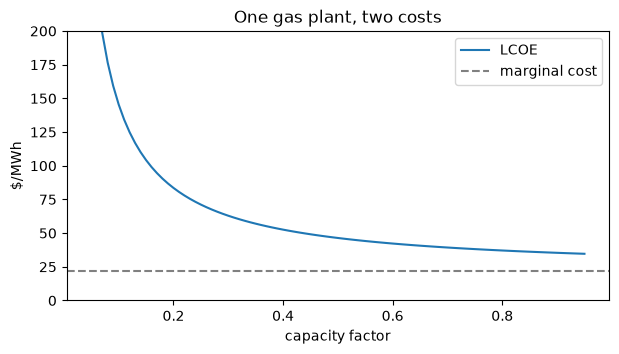

Line chart of levelized cost against capacity factor for the gas plant. A solid curve falls steeply from about $269/MWh at a 5% capacity factor and flattens towards $35/MWh at 95%; a dashed horizontal line marks the $21.63/MWh marginal cost, which the curve approaches but never reaches.


In [11]:
import matplotlib.pyplot as plt

def levelized(cf, fixed, marginal):
    return fixed / (8760 * cf) + marginal

assert relative(levelized(cf_gas, fixed, gas_mc), lcoe) < AGREEMENT_RTOL

cfs = [c / 100 for c in range(5, 96)]
plt.figure(figsize=(7, 3.5))
plt.plot(cfs, [levelized(c, fixed, gas_mc) for c in cfs], label='LCOE')
plt.axhline(gas_mc, ls='--', color='grey', label='marginal cost')
plt.ylim(0, 200); plt.xlabel('capacity factor'); plt.ylabel('$/MWh')
plt.legend(); plt.title('One gas plant, two costs')
ALT_TEXT = (f'Line chart of levelized cost against capacity factor for the gas '
            f'plant. A solid curve falls steeply from about '
            f'${levelized(0.05, fixed, gas_mc):.0f}/MWh at a 5% capacity factor and '
            f'flattens towards ${levelized(0.95, fixed, gas_mc):.0f}/MWh at 95%; a '
            f'dashed horizontal line marks the ${gas_mc:.2f}/MWh marginal cost, which '
            f'the curve approaches but never reaches.')
plt.show()
print(ALT_TEXT)


> A peaking plant runs a few hundred hours a year. Where on this curve does it sit, and why would anyone build one?

*Before class: the industrial park of the book's section 1.4 draws 50 MW; the same site as a data center draws 500 MW, all year. How many of your Part B houses is each, in electricity alone - and is the plant in Part C the one that would serve it?*

### Sources
- U.S. EIA, energy conversion factors (Btu per kWh, therm, gallon of gasoline; MMBtu per Mcf of natural gas).
- U.S. EPA, GHG emission factors hub (kg CO2 per MMBtu).
- NREL, National Solar Radiation Database (global horizontal irradiance).
- Plant data: the Houston combined cycle and the coal plant of the book's sections 9.3 and 9.4.


---
## Explore - for your reflection

Nothing above changes. These cells read its numbers. Two kinds: **sliders** (move one, watch what follows) and **edit-and-run** cells (change a number or write a line yourself). Answer the numbered questions in your reflection.

### Slide it: which plant runs first?


In [12]:
from ipywidgets import interact, FloatSlider

def merit(gas_price_mcf=2.65, coal_price_ton=18.76, co2_price=0.0):
    gas = gas_hr * (gas_price_mcf / 1.033 + 0.50) + 2.10 + co2_price * gas_t
    coal = coal_hr * (coal_price_ton / 15.97 + 0.75) + 5.06 + co2_price * coal_t
    print(f'gas ${gas:.2f}/MWh   coal ${coal:.2f}/MWh   ->  '
          f'{"gas" if gas < coal else "coal"} runs first')
    plt.figure(figsize=(6, 2))
    plt.barh(['coal', 'gas'], [coal, gas], color=['#6b4f3a', '#1f77b4'])
    plt.xlim(0, 120); plt.xlabel('$/MWh')
    ALT_TEXT = (f'Two horizontal bars, labelled coal and gas: coal ${coal:.2f}/MWh, '
                f'gas ${gas:.2f}/MWh. The shorter bar runs first.')
    plt.show()

interact(merit,
         gas_price_mcf=FloatSlider(min=1, max=10, step=0.05, value=2.65, description='gas $/Mcf'),
         coal_price_ton=FloatSlider(min=5, max=60, step=0.5, value=18.76, description='coal $/ton'),
         co2_price=FloatSlider(min=0, max=100, step=0.5, value=0, description='CO2 $/t'));


interactive(children=(FloatSlider(value=2.65, description='gas $/Mcf', max=10.0, min=1.0, step=0.05), FloatSli…

> **1.** At today's fuel prices, raise the CO2 price from zero. Does the order ever change? Now set gas to about **$5.80/Mcf** - the plant-gate price doubled - and find the CO2 price where the two plants swap.
>
> **2.** At the swap, the two bars are the same length. Write the equation that says so and solve it for the CO2 price by hand. Does it match the slider?

### Slide it: what makes up the levelized cost?


In [13]:
def lcoe_parts(capex_per_mw=1_176_000, capacity_factor=0.30, rate=0.07, years=30):
    crf_here = rate * (1 + rate) ** years / ((1 + rate) ** years - 1)
    mwh = 8760 * capacity_factor                 # per MW per year
    parts = {'capital': capex_per_mw * crf_here / mwh,
             'fixed O&M': 13_730 / mwh,
             'fuel + VOM': gas_mc}
    total = sum(parts.values())
    print(f'LCOE ${total:.2f}/MWh = ' +
          ' + '.join(f'{k} ${v:.2f}' for k, v in parts.items()))
    plt.figure(figsize=(6, 1.8))
    left = 0
    for (name, v), hatch in zip(parts.items(), ('//', '..', '')):   # not colour alone
        plt.barh(['LCOE'], [v], left=left, label=name, hatch=hatch)
        left += v
    plt.xlim(0, 250); plt.xlabel('$/MWh'); plt.legend(fontsize=8)
    ALT_TEXT = ('One stacked horizontal bar of the levelized cost, left to right: '
                + ', '.join(f'{k} ${v:.2f}' for k, v in parts.items())
                + f', totalling ${total:.2f}/MWh.')
    plt.show()

interact(lcoe_parts,
         capex_per_mw=FloatSlider(min=300_000, max=4_000_000, step=25_000, value=1_176_000, description='capex $/MW'),
         capacity_factor=FloatSlider(min=0.05, max=0.95, step=0.01, value=0.30, description='capacity f.'),
         rate=FloatSlider(min=0.02, max=0.15, step=0.005, value=0.07, description='rate'),
         years=FloatSlider(min=10, max=40, step=1, value=30, description='years'));


interactive(children=(FloatSlider(value=1176000.0, description='capex $/MW', max=4000000.0, min=300000.0, step…

> **3.** Which slider moves the LCOE most for a small nudge? Is it the same slider at a 10 percent capacity factor as at 90 percent?
>
> **4.** Find the capacity factor at which capital is half the LCOE. A wind farm has no fuel bar at all and runs at about 40 percent: what would its capital cost have to be for its LCOE to match this plant's at 87 percent?

### Slide it: the average wind is not the average power


In [14]:
def windy_site(mean_speed=8.0, spread=0.0):
    lo, hi = max(mean_speed - spread, 0), mean_speed + spread
    p_lo = 0.5 * rho * area * lo ** 3 / 1e6
    p_hi = 0.5 * rho * area * hi ** 3 / 1e6
    p_mean = 0.5 * rho * area * mean_speed ** 3 / 1e6
    print(f'half the time {lo:.1f} m/s, half the time {hi:.1f} m/s')
    print(f'power at the average speed  {p_mean:6.2f} MW')
    print(f'average of the power        {(p_lo + p_hi) / 2:6.2f} MW')

interact(windy_site,
         mean_speed=FloatSlider(min=3, max=12, step=0.5, value=8, description='mean m/s'),
         spread=FloatSlider(min=0, max=6, step=0.5, value=0, description='± m/s'));


interactive(children=(FloatSlider(value=8.0, description='mean m/s', max=12.0, min=3.0, step=0.5), FloatSlider…

> **5.** Hold the mean at 8 m/s and widen the spread. Which line moves? What would you want to know about a site besides its average wind speed?
>
> **6.** Above about 12 m/s a real turbine stops producing more. Which of the two lines does that limit change, and in which direction?

### Edit and run: a third plant

Write the three missing lines yourself, using Parts C, D and F as the pattern. The inputs are round illustrative numbers; replace them with ones you can cite (NREL ATB, EIA).


In [15]:
# a nuclear plant
nuc_hr = 10.4               # MMBtu of heat per MWh - fission heat counts the same way
nuc_fuel = 0.70             # $/MMBtu, enriched and fabricated fuel
nuc_vom = 2.40              # $/MWh
nuc_capex = 7_000_000       # $/MW
nuc_fixed_om = 130_000      # $/MW-year
nuc_cf = 0.93

nuc_mc = None               # ___ marginal cost, $/MWh   (Part C)
nuc_t = None                # ___ tonnes CO2 per MWh     (Part D) - and why?
nuc_lcoe = None             # ___ levelized cost, $/MWh  (Part F: use crf)

print('nuclear: marginal cost', nuc_mc, ' CO2', nuc_t, ' LCOE', nuc_lcoe)


nuclear: marginal cost None  CO2 None  LCOE None


> **7.** Rank the three plants by marginal cost, then by LCOE. Do the two rankings agree? Now put a $50 a tonne CO2 price on gas and coal (the first slider shows what it does to them): does nuclear's place in either ranking move?
